# 08 – NHL EDGE data (2025-26)

Notebook 07 pulled skating and shot data live from the NHL for one player at a time. This notebook downloads it **once for every skater** and saves it, so:
- cards load instantly and work offline
- the NHL's server isn't hit every time a card is drawn
- EDGE stats get **our own percentiles**, calculated the same way as every other row on the card (vs. qualified players at the same position)

Each player's raw response is saved as its own file in `data/edge_raw/2025-26/`. If the download stops partway, run it again and it picks up where it left off. The raw files stay on this computer (they're in `.gitignore`).

NHL EDGE data exists from 2021-22 on, so the same code works for all five seasons later.

Source: NHL EDGE (api-web.nhle.com), regular season.

## 1. Setup

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from war_model import run_season, V04_PARAMS
from edge_data import download_season, build_table
from player_card import build_metrics, add_percentiles, add_edge, draw_card

DATA = Path("../data")
SEASON_FILE = DATA / "skaters25-26.csv"
SEASON_LABEL = "2025-26"
SEASON_CODE = "20252026"
RAW_DIR = DATA / "edge_raw" / SEASON_LABEL

war = run_season(SEASON_FILE, V04_PARAMS)
player_ids = war["playerId"].tolist()
print("Skaters to download:", len(player_ids))

Skaters to download: 940


## 2. Download
About 10 minutes for a full season. Progress prints every 50 players. If it stops or anything fails, just run this cell again.

In [2]:
failed = download_season(player_ids, SEASON_CODE, RAW_DIR)

0 already saved, 940 to download (about 9 minutes)
  50 / 940
  100 / 940
  150 / 940
  200 / 940
  250 / 940
  300 / 940
  350 / 940
  400 / 940
  450 / 940
  500 / 940
  550 / 940
  600 / 940
  650 / 940
  700 / 940
  750 / 940
  800 / 940
  850 / 940
  900 / 940
  940 / 940
Done, no failures.


## 3. Build the table

In [3]:
edge = build_table(RAW_DIR)
edge.to_csv(DATA / f"edge_{SEASON_LABEL}.csv", index=False)

names = war[["playerId", "name", "team", "position", "games_played"]]
edge = edge.merge(names, on="playerId", how="left")

print("Saved", len(edge), "players to", f"data/edge_{SEASON_LABEL}.csv")
print("With EDGE data:", int(edge["has_edge"].sum()), "| without:", int((~edge["has_edge"]).sum()))
print("\nPlayers without EDGE data (fewest games first):")
print(edge[~edge["has_edge"]].sort_values("games_played")[["name", "team", "games_played"]].head(10).to_string(index=False))

Saved 940 players to data/edge_2025-26.csv
With EDGE data: 940 | without: 0

Players without EDGE data (fewest games first):
Empty DataFrame
Columns: [name, team, games_played]
Index: []


### Sanity check: fastest skaters and hardest shots
These should match the names you'd expect.

In [4]:
print("Top skating speed (mph)")
print(edge.nlargest(10, "top_speed")[["name", "team", "position", "top_speed"]].round(2).to_string(index=False))
print("\nTop shot speed (mph)")
print(edge.nlargest(10, "shot_speed")[["name", "team", "position", "shot_speed"]].round(2).to_string(index=False))

Top skating speed (mph)
            name team position  top_speed
  Beck Malenstyn  BUF        L      24.94
Nathan MacKinnon  COL        C      24.78
  Connor McDavid  EDM        C      24.61
    Logan Cooley  UTA        C      24.38
  Jake Sanderson  OTT        D      24.37
    Ryan Leonard  WSH        R      24.26
    Bobby McMann  SEA        C      24.25
    Trevor Moore  LAK        L      24.22
     Cole Koepke  WPG        L      24.22
    Owen Tippett  PHI        R      23.97

Top shot speed (mph)
           name team position  shot_speed
   Tyler Kleven  OTT        D      103.51
  Morgan Geekie  BOS        C      103.03
    Ryan Pulock  NYI        D      103.01
  Louis Crevier  CHI        D      102.83
    J.T. Miller  NYR        C      102.58
   Colin Miller  WPG        D      102.47
    Jake Walman  EDM        D      101.97
Brandon Montour  SEA        D      101.56
  Victor Hedman  TBL        D      101.42
  Conor Timmins  BUF        D      101.12


## 4. Our percentiles vs. the NHL's
The NHL publishes its own percentiles, but it doesn't say who they compare against. Ours compare each player to qualified players at his position, same as the rest of the card. If the two line up closely, both are measuring the same thing.

In [5]:
cards = add_edge(add_percentiles(build_metrics(war, SEASON_FILE)), build_table(RAW_DIR))

compare = {}
for key in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]:
    ok = cards["qualified"] & cards["has_edge"]
    compare[key] = {pos: cards.loc[ok & (cards["pos_group"] == pos), f"pct_{key}"]
                         .corr(cards.loc[ok & (cards["pos_group"] == pos), f"nhl_pct_{key}"] * 100)
                    for pos in ["F", "D"]}
pd.DataFrame(compare).T.rename(columns={"F": "Forwards r", "D": "Defense r"}).round(3)

,Forwards r,Defense r
top_speed,0.997,0.997
bursts_20,0.997,0.995
shot_speed,0.998,0.999
oz_pct_ev,1.000,1.000


In [6]:
seider = cards[cards["name"] == "Moritz Seider"].iloc[0]
pd.DataFrame({
    "value": [seider[k] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
    "our percentile": [seider[f"pct_{k}"] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
    "NHL percentile": [100 * seider[f"nhl_pct_{k}"] for k in ["top_speed", "bursts_20", "shot_speed", "oz_pct_ev"]],
}, index=["Top speed", "Bursts over 20", "Shot speed", "O-zone time (EV)"]).round(2)

,value,our percentile,NHL percentile
Top speed,21.72,39.0,51.85
Bursts over 20,43.00,67.0,74.38
Shot speed,98.93,91.0,92.88
O-zone time (EV),0.42,52.0,50.67


## 5. Seider's card, from the saved data
Same card as notebook 07, but the EDGE rows now use our percentiles and nothing is fetched live.

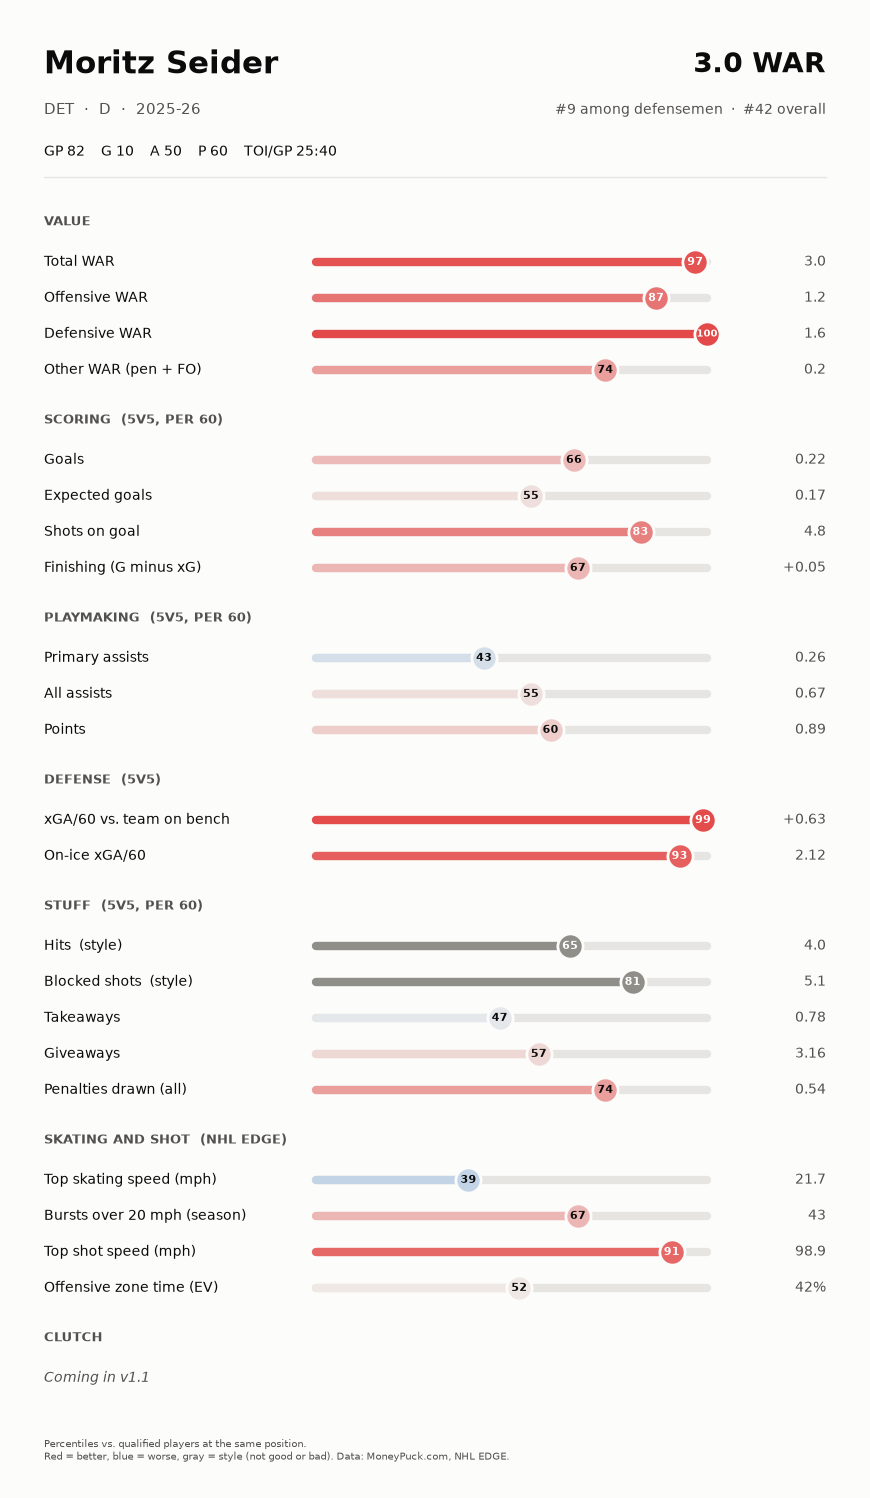

In [7]:
fig = draw_card(seider, SEASON_LABEL, path=Path("../images/cards") / "seider_2025-26.png")
plt.show()

In [8]:
cards.to_csv(DATA / f"cards_{SEASON_LABEL}.csv", index=False)
print("Saved the full card table (WAR, stats, EDGE, all percentiles) to", f"data/cards_{SEASON_LABEL}.csv")

Saved the full card table (WAR, stats, EDGE, all percentiles) to data/cards_2025-26.csv


## Next
- Check about 10 cards against hockey knowledge.
- Streamlit app: search a player, see his card. It will read `data/cards_2025-26.csv`, so it never needs to call the NHL.